# 01 - Fraud Data Exploration
## AEGIS: Enterprise AI Governance & Fraud Intelligence Platform

---

## Project Context

AEGIS is a production-grade enterprise platform for governing AI use cases in regulated financial environments. This notebook is part of the fraud detection module, one of the core showcases of the platform.

The fraud detection service uses an XGBoost model trained on realistic transaction data to score incoming transactions in real time. Flagged transactions are routed to an agentic investigation console powered by Claude Agent SDK and MCP tool calls.

---

## Dataset Information

**Dataset:** Credit Card Transactions Fraud Detection (Sparkov Simulation)  
**Source:** Kaggle, kartik2112  
**License:** CC0 Public Domain  
**Generator:** Sparkov Data Generation tool by Brandon Harris  

**Files:**
- `fraudTrain.csv`: Training transactions
- `fraudTest.csv`: Test transactions

**Key columns:**
- `trans_date_trans_time`: Transaction timestamp
- `amt`: Transaction amount
- `merchant`: Merchant name
- `category`: Merchant category
- `city`, `state`, `zip`: Customer location
- `lat`, `long`: Customer coordinates
- `merch_lat`, `merch_long`: Merchant coordinates
- `gender`: Customer gender
- `job`: Customer occupation
- `is_fraud`: Target label, 0 = legitimate, 1 = fraud

---

## Notebook Goals

1. Understand the shape and structure of the data
2. Analyze fraud rate and class imbalance
3. Explore transaction patterns by amount, time, category, location
4. Identify key features for the XGBoost model
5. Document findings that inform feature engineering in notebook 02

## 1. Setup and Configuration

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
from pathlib import Path
import datetime

In [3]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
FIGSIZE = (12, 5)

print("Setup complete. Random seed:", RANDOM_SEED)

from pathlib import Path

BASE_DIR = Path().resolve().parent
DATA_DIR = BASE_DIR / "data" / "raw"

TRAIN_PATH = DATA_DIR / "fraudTrain.csv"
TEST_PATH = DATA_DIR / "fraudTest.csv"
WIRE_PATH = DATA_DIR / "Wire transfer fraud.csv"

print("Base dir:", BASE_DIR)
print("Train exists:", TRAIN_PATH.exists())
print("Test exists:", TEST_PATH.exists())

print("Notebook run:", datetime.datetime.now().strftime("%Y-%m-%d %H:%M"))

Setup complete. Random seed: 42
Base dir: D:\Workspace\Projects\AI_ML\AIGES
Train exists: True
Test exists: True
Notebook run: 2026-10-05 21:20


## 2. Load Data

In [4]:
train = pd.read_csv(TRAIN_PATH,  index_col=0)
test = pd.read_csv(TEST_PATH,  index_col=0)

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"\nTrain memory: {train.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"\nTrain numeric features: {train.select_dtypes(include='number').shape[1]}")
print(f"Train categorical features: {train.select_dtypes(include='object').shape[1]}")
print(f"\nTrain categorical columns: {train.select_dtypes(include='object').columns.tolist()}")


Train shape: (1296675, 22)
Test shape: (555719, 22)

Train memory: 1085.3 MB

Train numeric features: 10
Train categorical features: 12

Train categorical columns: ['trans_date_trans_time', 'merchant', 'category', 'first', 'last', 'gender', 'street', 'city', 'state', 'job', 'dob', 'trans_num']


## Section 1: Credit Card Fraud Dataset Exploration

### 1.1 Basic Info

## Data Dictionary: Credit Card Fraud Dataset (Sparkov)

| Column | Type | Description |
|--------|------|-------------|
| `trans_date_trans_time` | object | Transaction datetime, format YYYY-MM-DD HH:MM:SS |
| `cc_num` | int64 | Credit card number, anonymized |
| `merchant` | object | Merchant name |
| `category` | object | Merchant category, e.g. grocery, shopping, entertainment |
| `amt` | float64 | Transaction amount in USD |
| `first` | object | Cardholder first name |
| `last` | object | Cardholder last name |
| `gender` | object | Cardholder gender, M or F |
| `street` | object | Cardholder street address |
| `city` | object | Cardholder city |
| `state` | object | Cardholder state, 2 letter code |
| `zip` | int64 | Cardholder zip code |
| `lat` | float64 | Cardholder latitude |
| `long` | float64 | Cardholder longitude |
| `city_pop` | int64 | Population of cardholder city |
| `job` | object | Cardholder occupation |
| `dob` | object | Cardholder date of birth |
| `trans_num` | object | Unique transaction ID |
| `unix_time` | int64 | Transaction timestamp in Unix epoch format |
| `merch_lat` | float64 | Merchant latitude |
| `merch_long` | float64 | Merchant longitude |
| `is_fraud` | int64 | Target label, 0 = legitimate, 1 = fraud |

**Notes:**
- `trans_date_trans_time` and `unix_time` represent the same timestamp in different formats
- `lat`, `long` and `merch_lat`, `merch_long` can be used to calculate geo-distance between cardholder and merchant, a key fraud signal
- `first`, `last`, `street` are PII fields, will be dropped before model training
- `cc_num` is a unique card identifier useful for velocity features

In [5]:
display(train.head())
print(f"Shape: {train.shape}")
print(f"\nDtypes:\n{train.dtypes}")
print(f"\nMissing values:\n{train.isnull().sum()}")

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.08,-81.18,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.01,-82.05,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.89,-118.21,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.16,-118.19,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.18,-112.26,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.15,-112.15,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.23,-112.11,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.03,-112.56,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.42,-79.46,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.67,-78.63,0


Shape: (1296675, 22)

Dtypes:
trans_date_trans_time     object
cc_num                     int64
merchant                  object
category                  object
amt                      float64
first                     object
last                      object
gender                    object
street                    object
city                      object
state                     object
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                       object
dob                       object
trans_num                 object
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
dtype: object

Missing values:
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                  

### 1.2 Class Imbalance

In [6]:
target_dist = train['is_fraud'].value_counts(normalize=True) * 100
print("Fraud distribution:")
print(target_dist.round(2))
print(f"\nImbalance ratio: {target_dist[0]/target_dist[1]:.1f}:1")

print(f"\nFraud rate: {train['is_fraud'].mean() * 100:.2f}%")

Fraud distribution:
is_fraud
0   99.42
1    0.58
Name: proportion, dtype: float64

Imbalance ratio: 171.8:1

Fraud rate: 0.58%


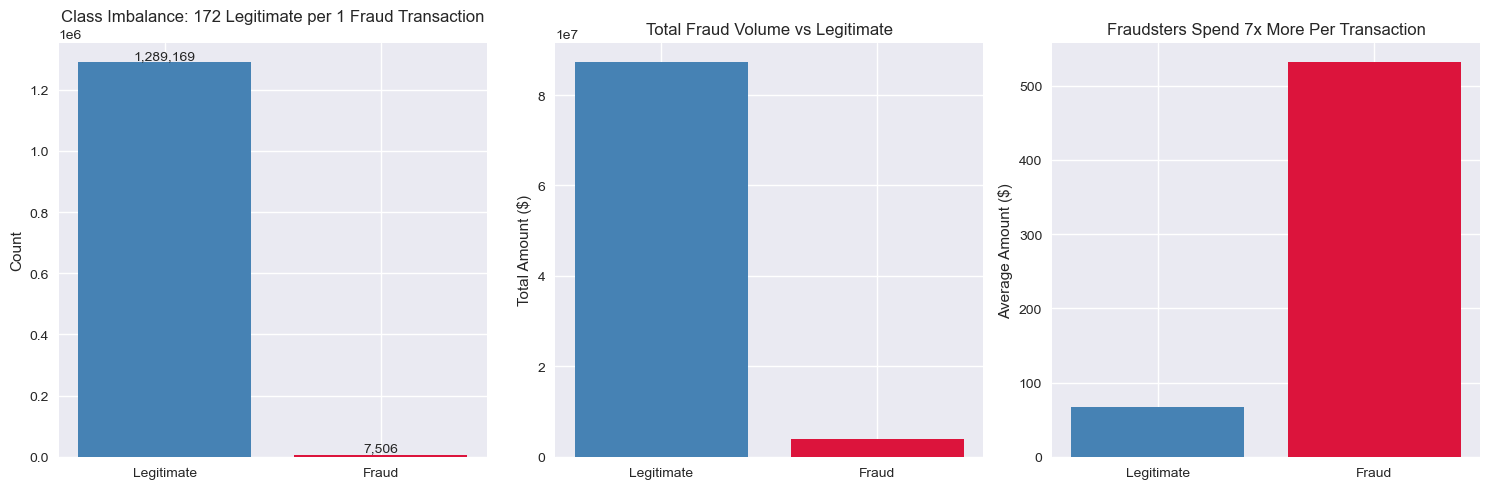

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

counts = train['is_fraud'].value_counts()
axes[0].bar(['Legitimate', 'Fraud'], counts.values, color=['steelblue', 'crimson'])
axes[0].set_title('Class Imbalance: 172 Legitimate per 1 Fraud Transaction')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')

axes[1].bar(['Legitimate', 'Fraud'], 
    [train[train['is_fraud']==0]['amt'].sum(), train[train['is_fraud']==1]['amt'].sum()],
    color=['steelblue', 'crimson'])
axes[1].set_title('Total Fraud Volume vs Legitimate')
axes[1].set_ylabel('Total Amount ($)')

axes[2].bar(['Legitimate', 'Fraud'],
    [train[train['is_fraud']==0]['amt'].mean(), train[train['is_fraud']==1]['amt'].mean()],
    color=['steelblue', 'crimson'])
axes[2].set_title('Fraudsters Spend 7x More Per Transaction')
axes[2].set_ylabel('Average Amount ($)')

plt.tight_layout()
plt.show()

### 1.3 Data Type Conversion & Cleanup

In [8]:
train.head(2)

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.08,-81.18,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.01,-82.05,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.89,-118.21,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.16,-118.19,0


##### Dropped Columns

| Column | Reason |
|--------|--------|
| `first`, `last`, `street` | PII with no predictive signal for fraud detection |
| `unix_time` | Duplicate timestamp, `trans_date_trans_time` is more readable |
| `trans_num` | Unique transaction identifier, no predictive value |
| `zip` | Redundant with `lat`/`long` which provide more precise location |

##### Kept for Feature Engineering

| Column | Planned Feature |
|--------|----------------|
| `cc_num` | Transaction velocity per card per hour |
| `dob` | Cardholder age |
| `lat`, `long`, `merch_lat`, `merch_long` | Geo distance between cardholder and merchant |

In [9]:
drop_cols = ['first', 'last', 'street', 'unix_time', 'trans_num', 'zip']

train = train.drop(columns=drop_cols)
test = test.drop(columns=drop_cols)

train['trans_date_trans_time'] = pd.to_datetime(train['trans_date_trans_time'])
train['dob'] = pd.to_datetime(train['dob'])

test['trans_date_trans_time'] = pd.to_datetime(test['trans_date_trans_time'])
test['dob'] = pd.to_datetime(test['dob'])

print(f"Train shape after cleaning: {train.shape}")
print(f"Test shape after cleaning: {test.shape}")
print(f"\nRemaining columns:\n{train.columns.tolist()}")
print(f"\nDtypes:\n{train.dtypes}")

Train shape after cleaning: (1296675, 16)
Test shape after cleaning: (555719, 16)

Remaining columns:
['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'gender', 'city', 'state', 'lat', 'long', 'city_pop', 'job', 'dob', 'merch_lat', 'merch_long', 'is_fraud']

Dtypes:
trans_date_trans_time    datetime64[ns]
cc_num                            int64
merchant                         object
category                         object
amt                             float64
gender                           object
city                             object
state                            object
lat                             float64
long                            float64
city_pop                          int64
job                              object
dob                      datetime64[ns]
merch_lat                       float64
merch_long                      float64
is_fraud                          int64
dtype: object


In [10]:
print(f"Duplicate rows: {train.duplicated().sum()}")
print(train['amt'].describe())
print(f"Date range: {train['trans_date_trans_time'].min()} to {train['trans_date_trans_time'].max()}")

Duplicate rows: 0
count   1296675.00
mean         70.35
std         160.32
min           1.00
25%           9.65
50%          47.52
75%          83.14
max       28948.90
Name: amt, dtype: float64
Date range: 2019-01-01 00:00:18 to 2020-06-21 12:13:37


Dataset spans January 2019 to June 2020. Monthly analysis by grouping across both years creates an imbalance:
- January to June: 2 years of data (2019 + 2020)
- July to December: 1 year of data (2019 only)

Monthly fraud rates for July to December are underrepresented and should be interpreted with caution. Year-level analysis in notebook 02 will address this.

Outlier detected: max of $28,948 compared to 75th percentile of $83 is a strong signal

In [11]:
print(f"Transactions above $1000: {(train['amt'] > 1000).sum()}")
print(f"Fraud rate above $1000: {train[train['amt'] > 1000]['is_fraud'].mean() * 100:.2f}%")
print(f"Fraud rate below $1000: {train[train['amt'] < 1000]['is_fraud'].mean() * 100:.2f}%")
print(f"\nTop 10 highest transactions:")
print(train.nlargest(10, 'amt')[['amt', 'category', 'is_fraud']])
print(f"\nTop 10 highest transactions indicating fraud:")
print(train[train['is_fraud'] == 1].nlargest(10, 'amt')[['amt', 'category', 'is_fraud']])

Transactions above $1000: 3936
Fraud rate above $1000: 24.11%
Fraud rate below $1000: 0.51%

Top 10 highest transactions:
             amt category  is_fraud
787549  28948.90   travel         0
793677  27390.12   travel         0
1234797 27119.77   travel         0
606211  26544.12   travel         0
352894  25086.94   travel         0
187885  17897.24   travel         0
1100138 15305.95   travel         0
752016  15047.03   travel         0
150564  15034.18   travel         0
1245847 14849.74   travel         0

Top 10 highest transactions indicating fraud:
            amt      category  is_fraud
1262544 1376.04  shopping_pos         1
514148  1371.81  shopping_pos         1
30239   1334.07  shopping_pos         1
1258483 1324.80  shopping_pos         1
821435  1313.18  shopping_pos         1
1258594 1312.98  shopping_net         1
872879  1294.83  shopping_net         1
75418   1292.21  shopping_net         1
531246  1289.89  shopping_net         1
878175  1289.07  shopping_net      



### Key Finding: Amount + Category = Better Signal Than Amount Alone

- Legitimate transactions dominate high amounts via travel category (up to $28,948)
- Fraudulent transactions peak around $1,376 in shopping_pos and shopping_net
- Fraud rate jumps from 0.51% below $1,000 to 24.11% above $1,000
- Rule engine should combine amount threshold with merchant category for precision

High risk: amount > $500 AND category = shopping_pos or shopping_net

Low risk:  amount > $10,000 AND category = travel

## Section 2: Feature Engineering & Type Conversion

### 2.1 DateTime Decomposition & Age Calculation

In [12]:
train['trans_date'] = train['trans_date_trans_time'].dt.date
train['trans_time'] = train['trans_date_trans_time'].dt.time
train['trans_hour'] = train['trans_date_trans_time'].dt.hour
train['trans_day'] = train['trans_date_trans_time'].dt.day
train['trans_month'] = train['trans_date_trans_time'].dt.month
train['trans_year'] = train['trans_date_trans_time'].dt.year
train['trans_dayofweek'] = train['trans_date_trans_time'].dt.dayofweek

train['age'] = (train['trans_date_trans_time'] - train['dob']).dt.days // 365

test['trans_date'] = test['trans_date_trans_time'].dt.date
test['trans_time'] = test['trans_date_trans_time'].dt.time
test['trans_hour'] = test['trans_date_trans_time'].dt.hour
test['trans_day'] = test['trans_date_trans_time'].dt.day
test['trans_month'] = test['trans_date_trans_time'].dt.month
test['trans_year'] = test['trans_date_trans_time'].dt.year
test['trans_dayofweek'] = test['trans_date_trans_time'].dt.dayofweek

test['age'] = (test['trans_date_trans_time'] - test['dob']).dt.days // 365

train = train.drop(columns=['trans_date_trans_time', 'dob'])
test = test.drop(columns=['trans_date_trans_time', 'dob'])

print(f"New columns: {train.columns.tolist()}")
print(f"\nAge range: {train['age'].min()} to {train['age'].max()}")
print(f"Hour range: {train['trans_hour'].min()} to {train['trans_hour'].max()}")

New columns: ['cc_num', 'merchant', 'category', 'amt', 'gender', 'city', 'state', 'lat', 'long', 'city_pop', 'job', 'merch_lat', 'merch_long', 'is_fraud', 'trans_date', 'trans_time', 'trans_hour', 'trans_day', 'trans_month', 'trans_year', 'trans_dayofweek', 'age']

Age range: 13 to 95
Hour range: 0 to 23


### 2.2 Categorical Encoding Check

In [13]:
print("Unique categories:", train['category'].nunique())
print(train['category'].value_counts())
print("\nUnique states:", train['state'].nunique())
print("\nGender distribution:\n", train['gender'].value_counts())

Unique categories: 14
category
gas_transport     131659
grocery_pos       123638
home              123115
shopping_pos      116672
kids_pets         113035
shopping_net       97543
entertainment      94014
food_dining        91461
personal_care      90758
health_fitness     85879
misc_pos           79655
misc_net           63287
grocery_net        45452
travel             40507
Name: count, dtype: int64

Unique states: 51

Gender distribution:
 gender
F    709863
M    586812
Name: count, dtype: int64


Data is clean and well structured. No dominant categories that would bias the model. Categorical encoding will be applied in notebook 02 before model training.

## Section 3: Exploratory Data Analysis

### 3.1 Amount Distribution

In [14]:
print(train['amt'].describe())
print(f"\nSkewness: {train['amt'].skew():.2f}")
print(f"\nAmount Distribution:")
print(f"Under $25:       {(train['amt'] < 25).sum() / len(train) * 100:.1f}%")
print(f"$25 to $50:      {((train['amt'] >= 25) & (train['amt'] < 50)).sum() / len(train) * 100:.1f}%")
print(f"$50 to $100:     {((train['amt'] >= 50) & (train['amt'] < 100)).sum() / len(train) * 100:.1f}%")
print(f"$100 to $500:    {((train['amt'] >= 100) & (train['amt'] < 500)).sum() / len(train) * 100:.1f}%")
print(f"$500 to $1000:   {((train['amt'] >= 500) & (train['amt'] < 1000)).sum() / len(train) * 100:.1f}%")
print(f"Over $1000:      {(train['amt'] >= 1000).sum() / len(train) * 100:.1f}%")

count   1296675.00
mean         70.35
std         160.32
min           1.00
25%           9.65
50%          47.52
75%          83.14
max       28948.90
Name: amt, dtype: float64

Skewness: 42.28

Amount Distribution:
Under $25:       35.7%
$25 to $50:      16.1%
$50 to $100:     30.0%
$100 to $500:    16.9%
$500 to $1000:   0.9%
Over $1000:      0.3%


In [15]:
print(train['amt'].describe())
print(f"\nSkewness: {train['amt'].skew():.2f}")
print(f"Transactions under $100: {(train['amt'] < 100).sum() / len(train) * 100:.1f}%")
print(f"Transactions under $500: {(train['amt'] < 500).sum() / len(train) * 100:.1f}%")
print(f"Transactions over $1000: {(train['amt'] > 1000).sum() / len(train) * 100:.1f}%")

count   1296675.00
mean         70.35
std         160.32
min           1.00
25%           9.65
50%          47.52
75%          83.14
max       28948.90
Name: amt, dtype: float64

Skewness: 42.28
Transactions under $100: 81.9%
Transactions under $500: 98.8%
Transactions over $1000: 0.3%


### Key Findings: Amount Distribution

- 82% of all transactions are under $100, typical everyday spending
- Extreme right skew (42.28), driven by legitimate travel transactions
- Only 0.3% of transactions exceed $1,000 but carry 24% fraud rate
- Fraudsters operate mostly in $500 to $1,400 range to avoid detection from the previous insights
- `amt` will be log transformed in notebook 02 to handle skewness before model training

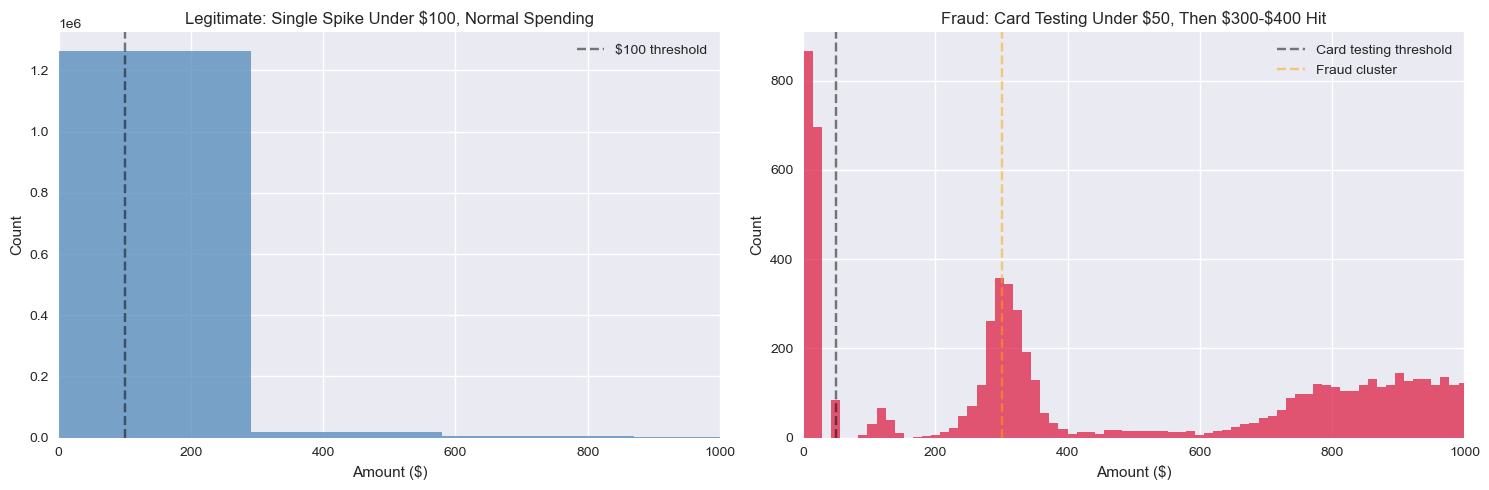

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(train[train['is_fraud']==0]['amt'], bins=100, color='steelblue', alpha=0.7)
axes[0].set_title('Legitimate: Single Spike Under $100, Normal Spending')
axes[0].set_xlabel('Amount ($)')
axes[0].set_ylabel('Count')
axes[0].set_xlim(0, 1000)
axes[0].axvline(x=100, color='black', linestyle='--', alpha=0.5, label='$100 threshold')
axes[0].legend()

axes[1].hist(train[train['is_fraud']==1]['amt'], bins=100, color='crimson', alpha=0.7)
axes[1].set_title('Fraud: Card Testing Under $50, Then $300-$400 Hit')
axes[1].set_xlabel('Amount ($)')
axes[1].set_ylabel('Count')
axes[1].set_xlim(0, 1000)
axes[1].axvline(x=50, color='black', linestyle='--', alpha=0.5, label='Card testing threshold')
axes[1].axvline(x=300, color='orange', linestyle='--', alpha=0.5, label='Fraud cluster')
axes[1].legend()

plt.tight_layout()
plt.show()

### Key Finding: Transaction Amount Distribution Patterns

**Observations:**
- Legitimate: single clean spike under $100, typical everyday spending
- Fraud cluster 1: under $50, card testing to verify stolen card works
- Fraud cluster 2: $300 to $400, actual fraudulent purchase after verification
- Fraud tail: flat and consistent from $600 to $1000, high value grabs
- Dip in fraud between $50 to $200, fraudsters avoid mid-range amounts

**Implications for AEGIS:**
- Amount alone is weak signal, needs category and velocity context
- Rule: small transaction followed by larger on same card within 30 min → flag
- Log transform `amt` before model training to handle extreme skew
- Sparkov data is too clean, real production data will need outlier handling

## Section 4: Time Pattern Analysis

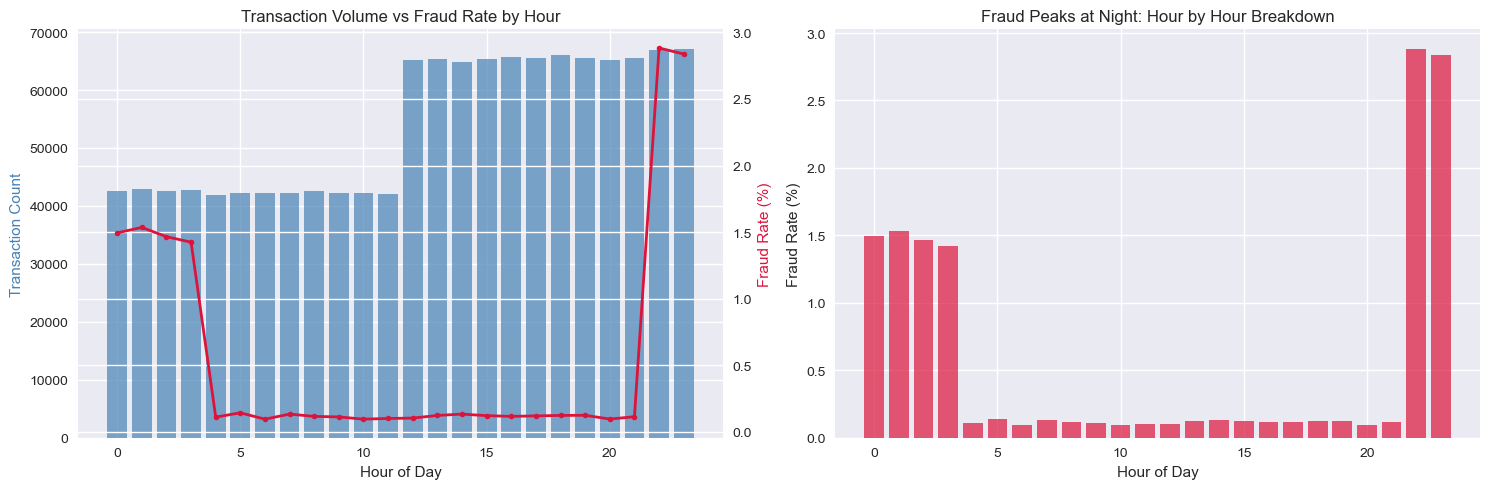

Highest fraud rate hour: 22:00
Lowest fraud rate hour: 6:00


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

hourly = train.groupby('trans_hour')['is_fraud'].agg(['mean', 'sum', 'count']).reset_index()
hourly['fraud_rate'] = hourly['mean'] * 100

axes[0].bar(hourly['trans_hour'], hourly['count'], color='steelblue', alpha=0.7)
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Transaction Count', color='steelblue')
axes[0].set_title('Transaction Volume vs Fraud Rate by Hour')

ax2 = axes[0].twinx()
ax2.plot(hourly['trans_hour'], hourly['fraud_rate'], color='crimson', linewidth=2, marker='o', markersize=4)
ax2.set_ylabel('Fraud Rate (%)', color='crimson')

axes[1].bar(hourly['trans_hour'], hourly['fraud_rate'], color='crimson', alpha=0.7)
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Fraud Rate (%)')
axes[1].set_title('Fraud Peaks at Night: Hour by Hour Breakdown')

plt.tight_layout()
plt.show()

print(f"Highest fraud rate hour: {hourly.loc[hourly['fraud_rate'].idxmax(), 'trans_hour']}:00")
print(f"Lowest fraud rate hour: {hourly.loc[hourly['fraud_rate'].idxmin(), 'trans_hour']}:00")

### 4.1 Fraud Rate by Hour of Day

**Observations:**
- Legitimate transactions peak after 12pm, consistent with lunch break and afternoon shopping behavior
- Fraud rate spikes sharply at 22:00 to 23:00, reaching nearly 3%, 5x the average rate
- Early morning 12am to 4am: low volume but elevated fraud rate, most transactions at this hour are suspicious
- Daytime 6am to 8pm: fraud rate near zero, safest window for transactions

**Implications:**
- Rule: transaction between 22:00 and 04:00 → increase risk score
- Rule: transaction between 00:00 and 04:00 with amount over $100 → auto flag
- Model should include `trans_hour` as a feature, strong fraud signal
- Fraud analysts should be staffed for evening shifts, not morning

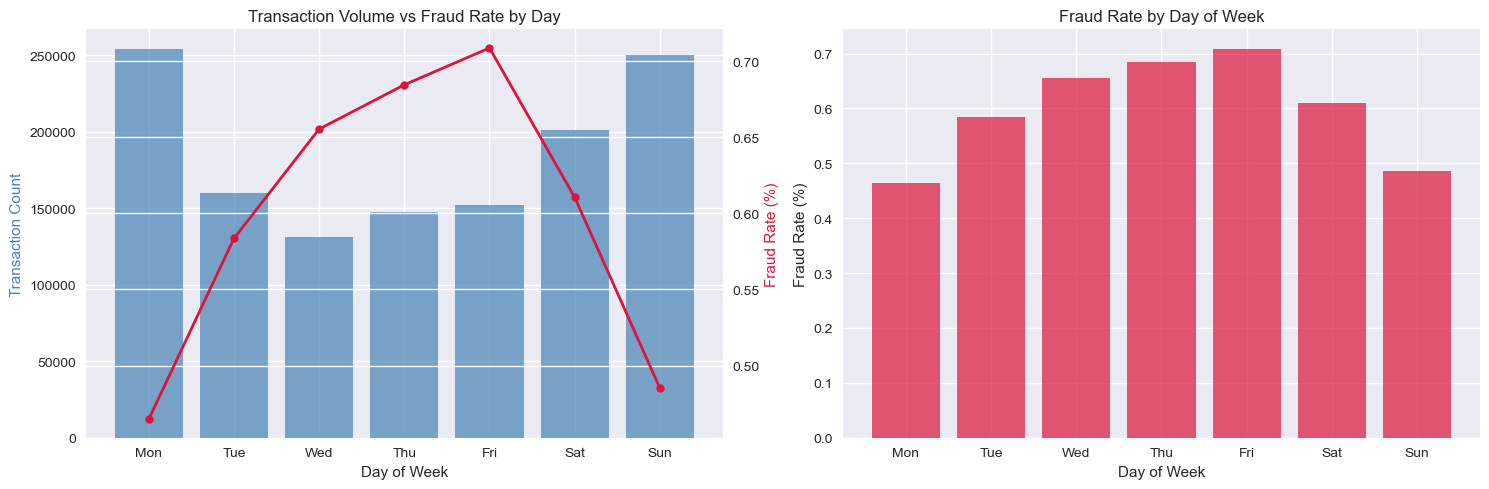

   trans_dayofweek  fraud_rate
0                0        0.46
1                1        0.58
2                2        0.66
3                3        0.68
4                4        0.71
5                5        0.61
6                6        0.49


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

daily = train.groupby('trans_dayofweek')['is_fraud'].agg(['mean', 'sum', 'count']).reset_index()
daily['fraud_rate'] = daily['mean'] * 100

axes[0].bar(days, daily['count'], color='steelblue', alpha=0.7)
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Transaction Count', color='steelblue')
axes[0].set_title('Transaction Volume vs Fraud Rate by Day')

ax2 = axes[0].twinx()
ax2.plot(days, daily['fraud_rate'], color='crimson', linewidth=2, marker='o', markersize=6)
ax2.set_ylabel('Fraud Rate (%)', color='crimson')

axes[1].bar(days, daily['fraud_rate'], color='crimson', alpha=0.7)
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Fraud Rate (%)')
axes[1].set_title('Fraud Rate by Day of Week')

plt.tight_layout()
plt.show()

print(daily[['trans_dayofweek', 'fraud_rate']].to_string())

### 4.2 Fraud Rate by Day of Week

**Observations:**
- Wednesday to Friday show highest fraud rates, peaking on Friday
- Weekend has high legitimate volume but lower fraud rate
- Monday is the safest day, lowest fraud rate of the week
- Fraud peaks on moderate volume days, not highest volume days

**Implication**
- Rule: transaction on Friday between 20:00 and 23:00 → highest risk combination
- Fraudsters exploit weekend gap, victims do not check statements until Monday
- Model should include `trans_dayofweek` as a feature
- Fraud analyst staffing should increase Thursday to Friday evening shifts

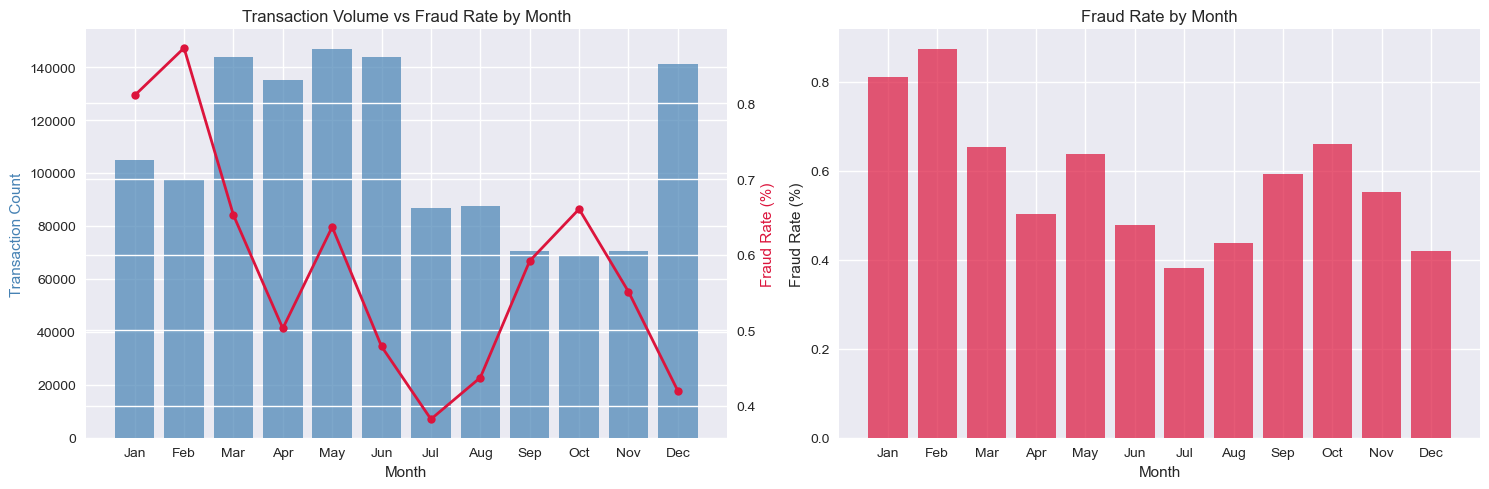

    trans_month  fraud_rate
0             1        0.81
1             2        0.87
2             3        0.65
3             4        0.50
4             5        0.64
5             6        0.48
6             7        0.38
7             8        0.44
8             9        0.59
9            10        0.66
10           11        0.55
11           12        0.42


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

monthly = train.groupby('trans_month')['is_fraud'].agg(['mean', 'sum', 'count']).reset_index()
monthly['fraud_rate'] = monthly['mean'] * 100
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

axes[0].bar(months, monthly['count'], color='steelblue', alpha=0.7)
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Transaction Count', color='steelblue')
axes[0].set_title('Transaction Volume vs Fraud Rate by Month')

ax2 = axes[0].twinx()
ax2.plot(months, monthly['fraud_rate'], color='crimson', linewidth=2, marker='o', markersize=6)
ax2.set_ylabel('Fraud Rate (%)', color='crimson')

axes[1].bar(months, monthly['fraud_rate'], color='crimson', alpha=0.7)
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Fraud Rate (%)')
axes[1].set_title('Fraud Rate by Month')

plt.tight_layout()
plt.show()

print(monthly[['trans_month', 'fraud_rate']].to_string())

### 4.3 Fraud Rate by Month

**Observations:**
- February has highest fraud rate, driven by Valentine's Day unusual spending patterns
- January elevated, fraudsters target newly activated Christmas gift cards
- December lowest fraud rate despite high shopping volume, banks increase monitoring during holidays
- Second half of year shows lower volume, dataset ends June 2020, incomplete data

**Implications**
- Rule: February transactions in gift categories → increase risk score
- Seasonal model retraining recommended, fraud patterns shift monthly
- December low fraud rate should not reduce monitoring, banks actively suppress it
- Data limitation: July to December fraud rates unreliable due to incomplete dataset

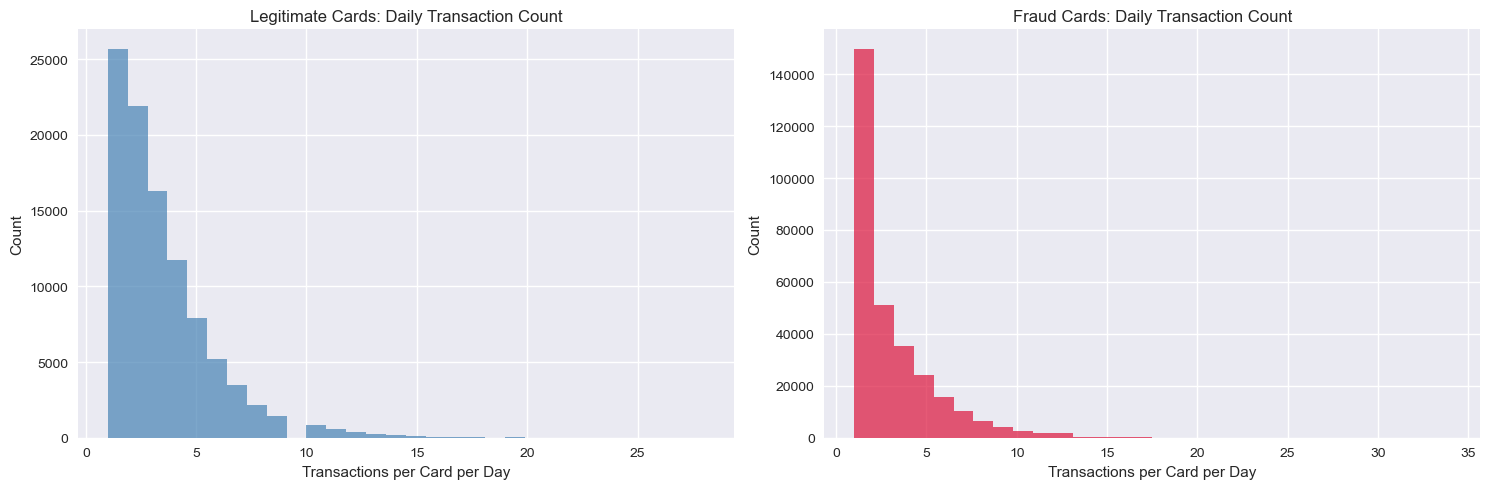

Avg daily transactions - Legitimate cards: 3.25
Avg daily transactions - Fraud cards: 3.21


In [23]:
transactions_per_card_per_day = train.groupby(['cc_num', 'trans_year', 'trans_month', 'trans_day']).size().reset_index(name='daily_transactions')

fraud_cards = train[train['is_fraud']==1]['cc_num'].unique()
transactions_per_card_per_day['is_fraud_card'] = transactions_per_card_per_day['cc_num'].isin(fraud_cards).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(transactions_per_card_per_day[transactions_per_card_per_day['is_fraud_card']==0]['daily_transactions'],
    bins=30, color='steelblue', alpha=0.7)
axes[0].set_title('Legitimate Cards: Daily Transaction Count')
axes[0].set_xlabel('Transactions per Card per Day')
axes[0].set_ylabel('Count')

axes[1].hist(transactions_per_card_per_day[transactions_per_card_per_day['is_fraud_card']==1]['daily_transactions'],
    bins=30, color='crimson', alpha=0.7)
axes[1].set_title('Fraud Cards: Daily Transaction Count')
axes[1].set_xlabel('Transactions per Card per Day')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

print(f"Avg daily transactions - Legitimate cards: {transactions_per_card_per_day[transactions_per_card_per_day['is_fraud_card']==0]['daily_transactions'].mean():.2f}")
print(f"Avg daily transactions - Fraud cards: {transactions_per_card_per_day[transactions_per_card_per_day['is_fraud_card']==1]['daily_transactions'].mean():.2f}")

### 4.4 Pseudo Velocity: Daily Transaction Count per Card

**Observations:**
- Both legitimate and fraud cards cluster at 1 to 5 transactions per day
- Fraud cards extend to 35 transactions per day vs 25 for legitimate cards
- Heavy tail in fraud distribution confirms velocity as a fraud signal
- Most fraud occurs on cards with moderate daily activity, not extreme outliers, fraudsters blend in

**Limitations:**
- This is pseudo velocity using daily counts, not true hourly velocity
- True velocity features (transactions in last 1 hour) will be engineered in notebook 02
- A card with 3 transactions in 10 minutes is more suspicious than 3 transactions across a day

**Implications:**
- Rule: more than 10 transactions on same card in one day → flag for review
- True velocity rule: more than 3 transactions on same card within 1 hour → auto escalate
- `daily_transaction_count` will be engineered as a feature in notebook 02

## Section 5: Merchant Category Analysis

### 5.1 Fraud Rate by Category

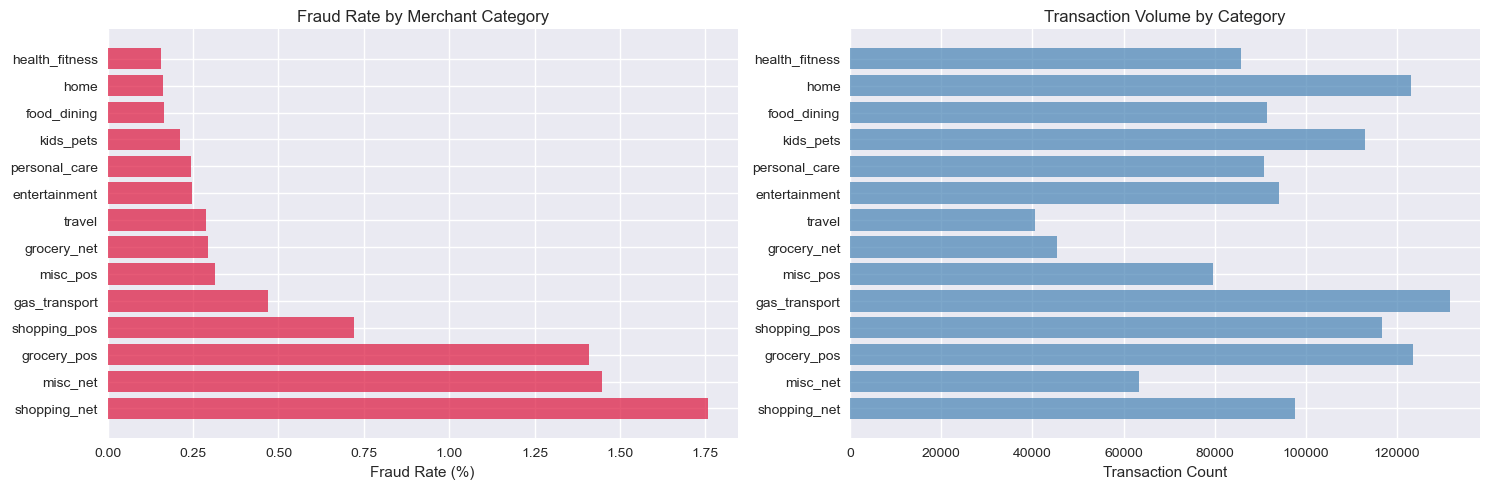

          category  fraud_rate   count
11    shopping_net        1.76   97543
8         misc_net        1.45   63287
4      grocery_pos        1.41  123638
12    shopping_pos        0.72  116672
2    gas_transport        0.47  131659
9         misc_pos        0.31   79655
3      grocery_net        0.29   45452
13          travel        0.29   40507
0    entertainment        0.25   94014
10   personal_care        0.24   90758
7        kids_pets        0.21  113035
1      food_dining        0.17   91461
6             home        0.16  123115
5   health_fitness        0.15   85879


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

category = train.groupby('category')['is_fraud'].agg(['mean', 'sum', 'count']).reset_index()
category['fraud_rate'] = category['mean'] * 100
category = category.sort_values('fraud_rate', ascending=False)

axes[0].barh(category['category'], category['fraud_rate'], color='crimson', alpha=0.7)
axes[0].set_xlabel('Fraud Rate (%)')
axes[0].set_title('Fraud Rate by Merchant Category')

axes[1].barh(category['category'], category['count'], color='steelblue', alpha=0.7)
axes[1].set_xlabel('Transaction Count')
axes[1].set_title('Transaction Volume by Category')

plt.tight_layout()
plt.show()

print(category[['category', 'fraud_rate', 'count']].to_string())

### 5.1 Fraud Rate by Merchant Category

**1. Shopping categories are the primary fraud channel**
`shopping_pos` and `shopping_net` have the highest fraud rates across all 14 categories. Fraudsters prefer retail purchases because they are easy to liquidate, gift cards, electronics, and clothing can be resold quickly. Both physical and online shopping are equally targeted.

**2. Miscellaneous categories are high risk despite low visibility**
`misc_net` and `misc_pos` rank second in fraud rate. Miscellaneous merchants are harder to monitor and categorize, making them attractive for fraudsters who want to avoid pattern detection. Vague category labels reduce rule engine precision.

**3. Grocery and gas are low fraud despite being high volume**
High frequency, low amount purchases. Fraudsters avoid them because the amounts are too small relative to detection risk. These categories can be treated as lower risk in the rule engine.

**4. Travel is the safest category despite highest transaction amounts**
Lowest fraud rate despite carrying the largest individual transaction amounts. Banks heavily monitor travel transactions and cardholders are more alert during travel spending.

**5. Online channels slightly riskier than physical**
`_net` suffix indicates online, `_pos` indicates physical point of sale. Online fraud is marginally higher because no physical card or PIN verification is required at checkout.

**Implications**
- Rule: `shopping_pos` or `shopping_net` AND `amt` > $200 → flag for review
- Rule: `misc_net` transaction from new device → escalate
- Category should be one-hot encoded as a feature in notebook 02
- Fraud analysts should prioritize shopping and misc category alerts

## Section 6: Geographic Analysis

### 6.1 Fraud Rate by State

In [27]:
import plotly.express as px

sample = train.sample(10000, random_state=RANDOM_SEED).copy()
sample['Transaction Type'] = sample['is_fraud'].map({0: 'Legitimate', 1: 'Fraud'})

fig = px.scatter_geo(
    sample,
    lat='lat',
    lon='long',
    color='Transaction Type',
    color_discrete_map={'Legitimate': 'steelblue', 'Fraud': 'crimson'},
    scope='usa',
    title='Transaction Locations: Fraud vs Legitimate',
    opacity=0.5
)

fig.show()

### 6.1 Geographic Distribution of Transactions

**Observations:**
- Transaction density highest on east coast, reflects US population distribution
- Fraud follows the same geographic distribution as legitimate transactions
- No specific geographic clusters of fraud detected
- Location alone is a weak fraud signal

**Key Insight:**
- What matters is not WHERE the transaction happens but HOW FAR it is from the cardholder
- A transaction 2,000 miles from the cardholder's home is suspicious regardless of which state it is in
- `geo_distance` between cardholder and merchant will be engineered in notebook 02

**Implications:**
- Do not use state as a fraud feature, use geo distance instead
- Rule: transaction more than 500 miles from cardholder home location → flag for review

In [29]:
state_fraud_filtered = state_fraud[state_fraud['count'] >= 1000]

fig = px.choropleth(
    state_fraud_filtered,
    locations='state',
    locationmode='USA-states',
    color='fraud_rate',
    scope='usa',
    color_continuous_scale=['steelblue', 'white', 'crimson'],
    title='Fraud Rate by State - Min 1000 Transactions',
    labels={'fraud_rate': 'Fraud Rate (%)'}
)

fig.show()

print(f"States removed due to low sample: {state_fraud[state_fraud['count'] < 1000]['state'].tolist()}")
print(f"\nTop 5 highest fraud states:")
print(state_fraud_filtered.nlargest(5, 'fraud_rate')[['state', 'fraud_rate', 'count']])
print(f"\nTop 5 lowest fraud states:")
print(state_fraud_filtered.nsmallest(5, 'fraud_rate')[['state', 'fraud_rate', 'count']])

States removed due to low sample: ['DE', 'RI']

Top 5 highest fraud states:
   state  fraud_rate  count
0     AK        1.70   2120
33    NV        0.84   5607
5     CO        0.81  13880
37    OR        0.80  18597
42    TN        0.80  17554

Top 5 lowest fraud states:
   state  fraud_rate  count
13    ID        0.20   5545
6     CT        0.21   7702
26    MT        0.27  11754
11    HI        0.27   2559
3     AZ        0.34  10770


### 6.2 Fraud Rate by State

**Observations:**
- Alaska highest fraud rate at 1.70%, likely unreliable due to small sample (2,120 transactions)
- Nevada second highest, driven by Las Vegas tourism and card not present activity
- Range extremely narrow: 0.20% to 1.70% across all states
- Delaware removed due to 100% fraud rate on only 9 transactions, classic small sample artifact

**Key Insight:**
- State level fraud rate varies minimally, weak standalone signal
- Small sample states produce misleading rates, minimum threshold of 1,000 transactions applied
- Geo distance between cardholder and merchant is a stronger signal than state

**Implications:**
- Drop `state` as a model feature, low predictive value
- Engineer `geo_distance` in notebook 02 using haversine formula
- Rule: transaction more than 500 miles from cardholder home → flag

## Section 7: Key Findings Summary & Feature Engineering Roadmap

### 7.1 Key Findings

| Finding | Insight | AEGIS Rule |
|---------|---------|------------|
| Class imbalance 172:1 | Model will need SMOTE or class weights | Handle in notebook 03 |
| Fraud averages 7x higher amount | Amount is a signal but not standalone | Combine with category |
| Two fraud amount clusters | Card testing under $50, then $300-$400 hit | Rule: small tx followed by large tx same card within 30 mins |
| Shopping categories dominate fraud | shopping_pos and shopping_net highest risk | Rule: shopping + amount > $200 → flag |
| Fraud peaks 22:00 to 23:00 | Fraudsters strike late night | Rule: transaction after 22:00 → increase risk score |
| Friday highest fraud day | Weekend gap exploitation | Increase monitoring Thursday to Friday evening |
| February highest fraud month | Valentine's Day unusual spending | Seasonal rule adjustment in February |
| Fraud cards reach 35 tx per day | Velocity is a fraud signal | Rule: more than 10 tx same card per day → flag |
| Geography weak signal | Fraud follows population distribution | Use geo distance not state |
| State range 0.20% to 1.70% | State alone not predictive | Drop state, engineer geo distance |

### 7.2 Features to Engineer in Notebook 02

| Feature | Description | Signal Strength |
|---------|-------------|----------------|
| `geo_distance` | Haversine distance between cardholder and merchant | High |
| `age` | Already created from dob | Medium |
| `transactions_last_1h` | Velocity per card per hour | High |
| `amt_last_1h` | Total amount per card per hour | High |
| `unique_merchants_1h` | Merchant diversity per card per hour | High |
| `log_amt` | Log transform of amount for skew | Medium |
| `is_night` | Binary flag for 22:00 to 06:00 | High |
| `is_weekend` | Binary flag for Saturday and Sunday | Low |
| `is_friday` | Binary flag for Friday | Medium |

### 7.3 Features to Drop in Notebook 02

| Feature | Reason |
|---------|--------|
| `state` | Weak signal, geo distance is better |
| `city` | Too many categories, low signal |
| `job` | No predictive value for fraud |
| `gender` | Weak signal, potential bias |
| `lat`, `long`, `merch_lat`, `merch_long` | Will be replaced by `geo_distance` |

### 7.4 Model Considerations for Notebook 03

- Handle 172:1 class imbalance with SMOTE or `scale_pos_weight` in XGBoost
- Log transform `amt` before training
- One hot encode `category` and `trans_dayofweek`
- Train on 2019 data, validate on 2020 data to respect time ordering
- Evaluate with precision recall AUC, not accuracy, imbalanced dataset